<a id="top"></a>
# sprint 2. Генераторы случайных величин для пьезоэлектрических материалов

В Sprint 1 исследованы три величины:

1. $X_1=e_{ij}^{\max}$ — максимальный пьезоэлектрический коэффициент, Кл/м²; выбранная модель — Ломакса, $\hat\alpha\approx1.568$, $\hat\lambda\approx0.473$.
2. $X_2=n$ — показатель преломления; выбранная модель — GEV, параметры из Sprint 1: $c\approx−0.281, loc\approx1.872, scale\approx0.513$ (в параметризации SciPy $c=-\xi$).
3. $X_3=V/N$ — объём на атом, $Å^3$/атом; выбранная модель — сдвинутое логнормальное распределение, $s\approx0.535, loc\approx3.902, scale\approx12.814$

**Цель спринта:** построить генераторы для всех трёх распределений, подробно обосновать два разных алгоритма для $X_1$, проверить генераторы тестами, сравнить моделируемые выборки с исходными данными и обсудить ограничения выбранных моделей.

<a id="data"></a>
## 1. Данные и воспроизводимость

Используются исходные файлы `data/piezo.json` и `data/matbench_dielectric_n_folds.csv` из Sprint 1. Для $X_1$ и $X_3$ берутся одни и те же записи соединений; $X_2$ — отдельная выборка Matbench. При повторном запуске фиксированный seed обеспечивает воспроизводимость последовательностей.

In [ ]:
from pathlib import Path
import json, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

SEED = 2026
DATA_DIR = Path("data")
PIEZO_PATH = DATA_DIR / "piezo.json"
DIEL_PATH = DATA_DIR / "matbench_dielectric_n_folds.csv"
if not PIEZO_PATH.exists() or not DIEL_PATH.exists():
    raise FileNotFoundError("Положите папку data рядом с ноутбуком. В ней нужны piezo.json и matbench_dielectric_n_folds.csv")

with PIEZO_PATH.open(encoding="utf-8") as f:
    raw_piezo = json.load(f)
piezo_rows = []
for row in raw_piezo:
    meta = row["meta"]
    if row.get("eij_max") is not None and meta.get("volume") and meta.get("nsites"):
        piezo_rows.append({"eij_max": float(row["eij_max"]),
                           "vol_atom": float(meta["volume"]) / float(meta["nsites"])})
piezo = pd.DataFrame(piezo_rows)
diel = pd.read_csv(DIEL_PATH)
x1 = piezo.loc[np.isfinite(piezo.eij_max) & (piezo.eij_max > 0), "eij_max"].to_numpy()
x2 = diel.loc[np.isfinite(diel.n) & (diel.n > 0), "n"].to_numpy()
x3 = piezo.loc[np.isfinite(piezo.vol_atom) & (piezo.vol_atom > 0), "vol_atom"].to_numpy()

print("Python:", platform.python_version(), " NumPy:", np.__version__, "Pandas:", pd.__version__)
print(f"N(X1)={len(x1)}, N(X2)={len(x2)}, N(X3)={len(x3)}")
display(pd.DataFrame({"RV": ["eij_max", "n", "V/N"], "N": [len(x1),len(x2),len(x3)],
                      "единица": ["Кл/м²", "безразмерная", "Å³/атом"]}))

Python: 3.13.18  NumPy: 2.4.6 Pandas: 2.2.3
N(X1)=941, N(X2)=4764, N(X3)=941


,RV,N,единица
0,eij_max,941,Кл/м²
1,n,4764,безразмерная
2,V/N,941,Å³/атом


<a id="math"></a>
## 2. Математические модели

### 2.1. $X_1=e_{ij}^{\max}$: распределение Ломакса

Для $x\geq0$, $\alpha>0$, $\lambda>0$:

$$f_X(x)=\frac{\alpha}{\lambda}\left(1+\frac{x}{\lambda}\right)^{-\alpha-1},\qquad
F_X(x)=1-\left(1+\frac{x}{\lambda}\right)^{-\alpha}.$$

Обратная функция находится непосредственно из $u=F_X(x)$:

$$Q_X(u)=\lambda\left((1-u)^{-1/\alpha}-1\right),\quad 0<u<1.$$

Если $U\sim U(0,1)$, то $P(Q_X(U)\leq x)=P(U\leq F_X(x))=F_X(x)$, следовательно, $Q_X(U)$ имеет распределение Ломакса.

**Моменты и хвост.** $E[X]=\lambda/(\alpha-1)$ при $\alpha>1$; $D[X]=\lambda^2\alpha/[(\alpha-1)^2(\alpha-2)]$ при $\alpha>2$. Момент порядка $r$ существует только при $r<\alpha$. Для оценки Sprint 1 $\hat\alpha\approx1.568$: математическое ожидание конечно, дисперсия бесконечна. Поэтому среднее существует, но чувствительно к экстремальным наблюдениям; медиана и квантили устойчивее. Хвост степенной: $P(X>x)=(1+x/\lambda)^{-\alpha}\sim (x/\lambda)^{-\alpha}$.

Ломакс — частный случай обобщённого распределения Парето (GPD) при положительном параметре формы $\xi=1/\alpha$ и масштабе $\beta=\lambda/\alpha$ в стандартной записи GPD. GPD возникает как предельная модель превышений над высоким порогом в теореме Пикандса–Балкема–де Хаана. Здесь это мотивация для тяжёлого хвоста, а не доказательство того, что исходные материалы являются независимыми превышениями порога.

### 2.2. $X_2=n$: обобщённое распределение экстремальных значений (GEV)

В параметризации экстремального значения:

$$F(x)=\exp\left[-\left(1+\xi\frac{x-\mu}{\sigma}\right)^{-1/\xi}\right],$$

где $\sigma>0$ и $1+\xi(x-\mu)/\sigma>0$. При $\xi\to0$ получаем распределение Гумбеля. Квантиль:

$$Q(u)=\mu+\frac{\sigma}{\xi}\left[(-\ln u)^{-\xi}-1\right],\quad \xi\ne0,$$

а при $\xi=0$: $Q(u)=\mu-\sigma\ln(-\ln u)$. В `scipy.stats.genextreme` параметр `c` имеет противоположный знак: $c=-\xi$. Поскольку в Sprint 1 $c\approx-0.281$, оценка $\xi\approx0.281$ соответствует тяжёлому правому хвосту и конечной верхней границе? При $\xi>0$ у GEV верхняя граница отсутствует, нижняя конечна. Моменты: при $\xi<1$ среднее существует,
$$E[X]=\mu+\frac{\sigma}{\xi}\left[\Gamma(1-\xi)-1\right],$$
а при $\xi<1/2$ существует дисперсия
$$D[X]=\frac{\sigma^2}{\xi^2}\left[\Gamma(1-2\xi)-\Gamma^2(1-\xi)\right].$$
В пределе $\xi\to0$ получаем среднее $\mu+\gamma\sigma$ и дисперсию $\pi^2\sigma^2/6$, где $\gamma$ — постоянная Эйлера. Для найденного $\hat\xi\approx0.281$ оба момента существуют.

### 2.3. $X_3=V/N$: сдвинутое логнормальное распределение

Пусть $X=\theta+\exp(Y)$, где $Y\sim N(m,s^2)$. Тогда для $x>\theta$:

$$f_X(x)=\frac{1}{(x-\theta)s\sqrt{2\pi}}\exp\left[-\frac{(\ln(x-\theta)-m)^2}{2s^2}\right],$$

$$F_X(x)=\Phi\left(\frac{\ln(x-\theta)-m}{s}\right),\quad
Q_X(u)=\theta+\exp(m+s\Phi^{-1}(u)).$$

В SciPy `shape=s`, `loc=theta`, `scale=exp(m)`. Логнормальность естественно появляется при мультипликативном формировании величины: произведение множества положительных факторов после логарифмирования превращается в сумму. Сдвиг $\theta$ задаёт нижнюю границу модели; он является параметром аппроксимации, а не автоматически установленным физическим минимальным объёмом атома.

### 2.4. Оценивание параметров

Параметры ниже оцениваются методом максимального правдоподобия (MLE). Для Ломакса при фиксированном `loc=0` логарифм правдоподобия:

$$\ell(\alpha,\lambda)=n\ln\alpha-n\ln\lambda-(\alpha+1)\sum_{i=1}^n\ln(1+x_i/\lambda).$$

Оценки — аргументы максимума этой функции. Для GEV и сдвинутой логнормальной модели используем численную MLE-оптимизацию SciPy. Сдвиг логнормального распределения может быть слабо идентифицируемым на конечной выборке, поэтому оценку `loc` нужно интерпретировать осторожно.

In [ ]:
par1 = stats.lomax.fit(x1, floc=0)          # (alpha, loc, scale=lambda)
par2 = stats.genextreme.fit(x2)             # (c=-xi, loc=mu, scale=sigma)
par3 = stats.lognorm.fit(x3)                # (s, loc=theta, scale=exp(m))

alpha_hat, _, lambda_hat = par1
c_hat, mu_hat, sigma_hat = par2
s_hat, theta_hat, scale_hat = par3
xi_hat = -c_hat
m_hat = np.log(scale_hat)

param_table = pd.DataFrame([
    ["Lomax", alpha_hat, 0.0, lambda_hat, "alpha, loc, scale"],
    ["GEV (SciPy c=-xi)", c_hat, mu_hat, sigma_hat, "c, loc, scale"],
    ["Shifted lognormal", s_hat, theta_hat, scale_hat, "s, loc, scale=exp(m)"],
], columns=["Модель", "параметр 1", "параметр 2", "параметр 3", "порядок параметров"])
display(param_table.round(6))
print(f"GEV xi={xi_hat:.6f}; lognormal m=ln(scale)={m_hat:.6f}")

,Модель,параметр 1,параметр 2,параметр 3,порядок параметров
0,Lomax,1.567971,0.000000,0.473409,"alpha, loc, scale"
1,GEV (SciPy c=-xi),-0.280691,1.871550,0.512618,"c, loc, scale"
2,Shifted lognormal,0.535104,3.901904,12.813689,"s, loc, scale=exp(m)"


GEV xi=0.280691; lognormal m=ln(scale)=2.550514


<a id="algorithms"></a>
## 3. Алгоритмы и реализация генераторов

### 3.1. Lomax — алгоритм A: метод обратной функции

Из равномерной последовательности $U_i$ вычисляем $X_i=Q(U_i)$. Преимущество — одна равномерная величина на один результат, явная формула и простая проверка. Недостаток — преобразование содержит логарифм и экспоненту (в численно устойчивой форме `log1p`/`expm1`).

### 3.2. Lomax — алгоритм B: гамма-экспоненциальная смесь

Это альтернативная конструкция, не использующая обратную функцию Lomax. Сначала генерируем $T\sim\mathrm{Gamma}(\alpha,\text{rate}=1)$, затем условно генерируем $X\mid T\sim\mathrm{Exp}(\text{rate}=T/\lambda)$.

Проверка плотности через интегрирование:

$$f_X(x)=\int_0^\infty \frac{t}{\lambda}e^{-tx/\lambda}
\frac{t^{\alpha-1}e^{-t}}{\Gamma(\alpha)}dt
=\frac{\alpha}{\lambda}(1+x/\lambda)^{-\alpha-1}.$$

Последнее равенство следует из интеграла Гамма-функции $\int_0^\infty t^\alpha e^{-bt}dt=\Gamma(\alpha+1)b^{-\alpha-1}$ и $\Gamma(\alpha+1)=\alpha\Gamma(\alpha)$. Значит, маргинальное распределение $X$ в точности Ломакс. Метод требует двух случайных шагов и может быть медленнее, зато демонстрирует представление тяжёлохвостого закона как смеси экспоненциальных распределений.

### 3.3. GEV — квантильное преобразование

Используем аналитическую квантильную формулу GEV. Для численной устойчивости граничные равномерные значения ограничиваем машинным интервалом $(0,1)$. Параметризация согласована с SciPy: $\xi=-c$.

### 3.4. Сдвинутая логнормальная — Box–Muller + экспонента

Метод Box–Muller строит пару независимых стандартных нормальных величин из двух независимых $U_1,U_2\sim U(0,1)$:

$$Z_1=\sqrt{-2\ln U_1}\cos(2\pi U_2),\quad
Z_2=\sqrt{-2\ln U_1}\sin(2\pi U_2).$$

Затем $Y=m+sZ$ и $X=\theta+e^Y$. Это даёт сдвинутую логнормальную модель. В отличие от GEV, где используется квантильное преобразование, здесь нормальная величина генерируется отдельным алгоритмом.

In [ ]:
def lomax_inverse(n, alpha, scale, rng=None):
    """Lomax через обратную функцию распределения."""
    if not isinstance(n, (int, np.integer)) or n < 0:
        raise ValueError("n должно быть целым неотрицательным")
    if not np.isfinite(alpha) or alpha <= 0 or not np.isfinite(scale) or scale <= 0:
        raise ValueError("alpha и scale должны быть положительными конечными числами")
    rng = np.random.default_rng() if rng is None else rng
    u = rng.random(n)
    return scale * np.expm1(-np.log1p(-u) / alpha)


def lomax_gamma_mixture(n, alpha, scale, rng=None):
    """Lomax как Gamma(alpha, rate=1) mixture of Exponential(rate=T/scale)."""
    if not isinstance(n, (int, np.integer)) or n < 0:
        raise ValueError("n должно быть целым неотрицательным")
    if not np.isfinite(alpha) or alpha <= 0 or not np.isfinite(scale) or scale <= 0:
        raise ValueError("alpha и scale должны быть положительными конечными числами")
    rng = np.random.default_rng() if rng is None else rng
    latent_rate = rng.gamma(shape=alpha, scale=1.0, size=n)
    latent_rate = np.maximum(latent_rate, np.finfo(float).tiny)
    return rng.exponential(scale=scale / latent_rate)


def gev_inverse(n, c, loc, scale, rng=None):
    """GEV через квантиль SciPy; c=-xi."""
    if n < 0 or int(n) != n or not np.isfinite(scale) or scale <= 0:
        raise ValueError("Некорректные n или scale")
    rng = np.random.default_rng() if rng is None else rng
    u = np.clip(rng.random(int(n)), np.nextafter(0.0, 1.0), np.nextafter(1.0, 0.0))
    return stats.genextreme.ppf(u, c, loc=loc, scale=scale)


def standard_normal_box_muller(n, rng=None):
    """n независимых N(0,1) значений методом Box–Muller."""
    if n < 0 or int(n) != n:
        raise ValueError("n должно быть целым неотрицательным")
    rng = np.random.default_rng() if rng is None else rng
    pairs = (int(n) + 1) // 2
    u1 = np.maximum(rng.random(pairs), np.finfo(float).tiny)
    u2 = rng.random(pairs)
    radius = np.sqrt(-2.0 * np.log(u1))
    z = np.empty(2 * pairs)
    z[0::2] = radius * np.cos(2 * np.pi * u2)
    z[1::2] = radius * np.sin(2 * np.pi * u2)
    return z[:int(n)]


def shifted_lognormal_box_muller(n, shape, loc, scale, rng=None):
    """X=loc+exp(Y), Y~N(log(scale), shape^2)."""
    if shape <= 0 or scale <= 0 or not np.isfinite(shape + loc + scale):
        raise ValueError("shape и scale должны быть положительными; параметры конечными")
    rng = np.random.default_rng() if rng is None else rng
    z = standard_normal_box_muller(n, rng)
    return loc + np.exp(np.log(scale) + shape * z)

rng_a = np.random.default_rng(SEED)
rng_b = np.random.default_rng(SEED + 1)
rng_c = np.random.default_rng(SEED + 2)
rng_d = np.random.default_rng(SEED + 3)
N_GEN = 100_000
gen_lomax_inv = lomax_inverse(N_GEN, alpha_hat, lambda_hat, rng_a)
gen_lomax_mix = lomax_gamma_mixture(N_GEN, alpha_hat, lambda_hat, rng_b)
gen_gev = gev_inverse(N_GEN, c_hat, mu_hat, sigma_hat, rng_c)
gen_lognorm = shifted_lognormal_box_muller(N_GEN, s_hat, theta_hat, scale_hat, rng_d)
print("Сгенерировано по 100 000 значений для каждой модели.")

Сгенерировано по 100 000 значений для каждой модели.


<a id="autotests"></a>
## 4. Автоматические тесты генераторов

Автотесты проверяют контракт функций (размерность, конечность, носитель), воспроизводимость по seed, обработку ошибочных аргументов и базовые статистические свойства стандартного нормального генератора. Статистические тесты не должны проходить «всегда»: при корректной модели вероятность случайного отклонения на уровне $\alpha=0.05$ составляет около 5%. Поэтому тесты не зашиваем как жёсткое условие `p > 0.05` для единственной случайной реализации; вместо этого показываем статистики и p-value.

In [ ]:
# Автотесты
for fn, args in [
    (lomax_inverse, (500, alpha_hat, lambda_hat)),
    (lomax_gamma_mixture, (500, alpha_hat, lambda_hat)),
    (gev_inverse, (500, c_hat, mu_hat, sigma_hat)),
    (shifted_lognormal_box_muller, (500, s_hat, theta_hat, scale_hat)),
]:
    out_a = fn(*args, rng=np.random.default_rng(777))
    out_b = fn(*args, rng=np.random.default_rng(777))
    assert out_a.shape == (500,)
    assert np.all(np.isfinite(out_a))
    assert np.array_equal(out_a, out_b), f"Воспроизводимость не выполнена: {fn.__name__}"

assert np.all(gen_lomax_inv >= 0) and np.all(gen_lomax_mix >= 0)
assert np.all(gen_lognorm > theta_hat)

if xi_hat > 0:
    gev_lower = mu_hat - sigma_hat / xi_hat
    assert np.all(gen_gev >= gev_lower - 1e-10)

for bad in [(lomax_inverse, (-2, 1, 1)), (lomax_gamma_mixture, (5, 0, 1))]:
    try:
        bad[0](*bad[1], rng=np.random.default_rng(1))
    except ValueError:
        pass
    else:
        raise AssertionError("Ожидалась ValueError для некорректных параметров")

z_test = standard_normal_box_muller(200_000, np.random.default_rng(1234))
assert abs(z_test.mean()) < 0.02
assert abs(z_test.std(ddof=1) - 1) < 0.02
print("Все автотесты контракта пройдены.")
print(f"Box–Muller: mean={z_test.mean():.4f}; sd={z_test.std(ddof=1):.4f}; skew={stats.skew(z_test):.4f}")

Все автотесты контракта пройдены.
Box–Muller: mean=-0.0005; sd=0.9985; skew=-0.0040


### 4.1. Статистический контроль равномерности и нормальности

Для алгоритмов, основанных на преобразованиях, полезно проверить промежуточные стандартные величины. У Lomax inverse величина $F_X(X)$ должна быть Uniform(0,1); для гамма-смеси прямое PIT также должно быть равномерным. Для Box–Muller проверяем нормальность $Z$ графически и по моментам. При больших $n$ формальные тесты очень чувствительны к малым отклонениям, поэтому интерпретируем их вместе с графиками.

PIT Lomax inverse: KstestResult(statistic=np.float64(0.0036186100926892673), pvalue=np.float64(0.14536328314836477), statistic_location=np.float64(0.47074138990731074), statistic_sign=np.int8(1))
PIT Lomax mixture: KstestResult(statistic=np.float64(0.004180711955241945), pvalue=np.float64(0.06048596449419941), statistic_location=np.float64(0.7181992880447581), statistic_sign=np.int8(1))
Box-Muller normal KS: KstestResult(statistic=np.float64(0.0015206528948426001), pvalue=np.float64(0.7435200148527504), statistic_location=np.float64(0.9763091120497432), statistic_sign=np.int8(1))


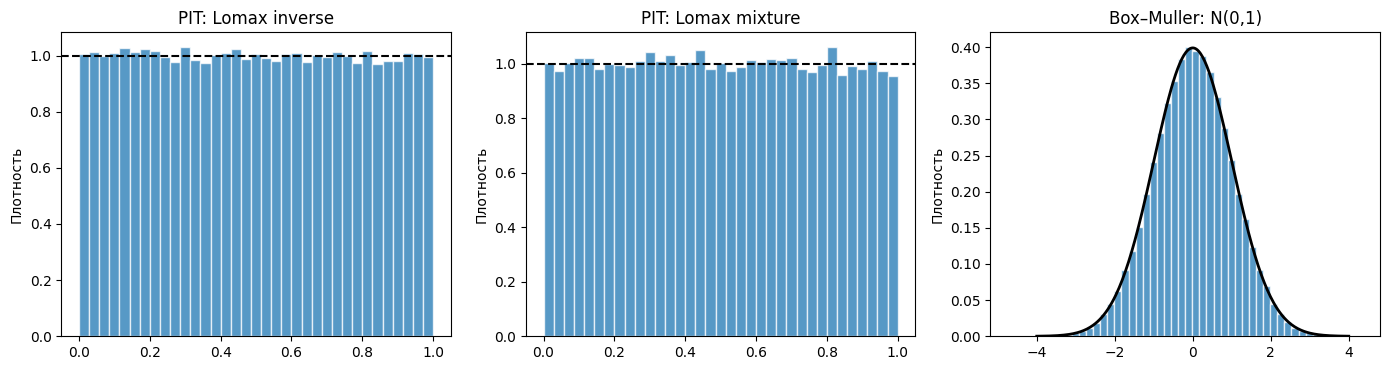

,генератор,KS D,p-value
0,Lomax inverse,0.003619,0.145363
1,Lomax mixture,0.004181,0.060486
2,GEV inverse,0.003831,0.105861
3,Shifted lognormal Box-Muller,0.001983,0.825881


In [ ]:
pit_inv = stats.lomax.cdf(gen_lomax_inv, alpha_hat, loc=0, scale=lambda_hat)
pit_mix = stats.lomax.cdf(gen_lomax_mix, alpha_hat, loc=0, scale=lambda_hat)
print("PIT Lomax inverse:", stats.kstest(pit_inv, "uniform"))
print("PIT Lomax mixture:", stats.kstest(pit_mix, "uniform"))
print("Box-Muller normal KS:", stats.kstest(z_test, "norm"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(pit_inv, bins=35, density=True, alpha=.75, edgecolor="white")
axes[0].axhline(1, ls="--", color="black"); axes[0].set_title("PIT: Lomax inverse")
axes[1].hist(pit_mix, bins=35, density=True, alpha=.75, edgecolor="white")
axes[1].axhline(1, ls="--", color="black"); axes[1].set_title("PIT: Lomax mixture")
axes[2].hist(z_test, bins=50, density=True, alpha=.75, edgecolor="white")
zz=np.linspace(-4,4,300); axes[2].plot(zz, stats.norm.pdf(zz), color="black", lw=2)
axes[2].set_title("Box–Muller: N(0,1)")
for ax in axes: ax.set_ylabel("Плотность")
plt.tight_layout(); plt.show()

pit_gev = stats.genextreme.cdf(gen_gev, c_hat, loc=mu_hat, scale=sigma_hat)
pit_lognorm = stats.lognorm.cdf(gen_lognorm, s_hat, loc=theta_hat, scale=scale_hat)
pit_all = pd.DataFrame([
    {"генератор":"Lomax inverse","KS D":stats.kstest(pit_inv,"uniform").statistic,"p-value":stats.kstest(pit_inv,"uniform").pvalue},
    {"генератор":"Lomax mixture","KS D":stats.kstest(pit_mix,"uniform").statistic,"p-value":stats.kstest(pit_mix,"uniform").pvalue},
    {"генератор":"GEV inverse","KS D":stats.kstest(pit_gev,"uniform").statistic,"p-value":stats.kstest(pit_gev,"uniform").pvalue},
    {"генератор":"Shifted lognormal Box-Muller","KS D":stats.kstest(pit_lognorm,"uniform").statistic,"p-value":stats.kstest(pit_lognorm,"uniform").pvalue},
])
display(pit_all.round(6))

<a id="comparison"></a>
## 5. Сравнение реальных и сгенерированных данных

Сравним реальные данные с независимой выборкой из подогнанной модели. Для $X_1$ отдельно сравниваем два алгоритма одного и того же распределения. Метрики: среднее, медиана, стандартное отклонение (только выборочное), квантили 90/95/99%, KS-статистика двух выборок и время генерации.

**Ограничение интерпретации:** если модель распределения не описывает эмпирические данные, генератор не сможет воспроизвести их полностью, даже если алгоритм генерации математически безошибочен. В Sprint 1 бутстреп-KS не отвергал Lomax для $X_1$ ($p\approx0.249$), но отвергал GEV для $X_2$ ($p\approx0.010$) и сдвинутую логнормальную модель для $X_3$ ($p\approx0.005$). Это различие должно отразиться в выводах.

In [ ]:
def describe_sample(name, arr):
    arr = np.asarray(arr)
    return {"Набор": name, "N": len(arr), "mean": np.mean(arr), "median": np.median(arr),
            "SD (sample)": np.std(arr, ddof=1), "q90": np.quantile(arr,.90),
            "q95": np.quantile(arr,.95), "q99": np.quantile(arr,.99)}

gen_lomax_inv_match = lomax_inverse(len(x1), alpha_hat, lambda_hat, np.random.default_rng(SEED+101))
gen_lomax_mix_match = lomax_gamma_mixture(len(x1), alpha_hat, lambda_hat, np.random.default_rng(SEED+102))
gen_gev_match = gev_inverse(len(x2), c_hat, mu_hat, sigma_hat, np.random.default_rng(SEED+103))
gen_lognorm_match = shifted_lognormal_box_muller(len(x3), s_hat, theta_hat, scale_hat, np.random.default_rng(SEED+104))

comparison = pd.DataFrame([
    describe_sample("X1 реальные", x1),
    describe_sample("X1 inverse", gen_lomax_inv_match),
    describe_sample("X1 gamma mixture", gen_lomax_mix_match),
    describe_sample("X2 реальные", x2),
    describe_sample("X2 GEV", gen_gev_match),
    describe_sample("X3 реальные", x3),
    describe_sample("X3 shifted lognormal", gen_lognorm_match),
]).set_index("Набор")

def theoretical_row(name, dist, params):
    q = dist.ppf([.90,.95,.99], *params)
    mean, var = dist.stats(*params, moments="mv")
    return {"Набор":name,"N":"теория","mean":float(mean),"median":float(dist.ppf(.5,*params)),
            "SD (sample)":float(np.sqrt(var)) if np.isfinite(var) and var >= 0 else np.nan,
            "q90":q[0],"q95":q[1],"q99":q[2]}

theory = pd.DataFrame([
    theoretical_row("X1 Lomax theory",stats.lomax,par1),
    theoretical_row("X2 GEV theory",stats.genextreme,par2),
    theoretical_row("X3 lognormal theory",stats.lognorm,par3),
]).set_index("Набор")
comparison = pd.concat([comparison, theory])
display(comparison.round(5))

ks_rows=[]
for label, real, simulated in [
    ("X1: inverse vs real", x1, gen_lomax_inv_match),
    ("X1: mixture vs real", x1, gen_lomax_mix_match),
    ("X1: inverse vs mixture", gen_lomax_inv_match, gen_lomax_mix_match),
    ("X2: GEV vs real", x2, gen_gev_match),
    ("X3: lognormal vs real", x3, gen_lognorm_match),
]:
    res=stats.ks_2samp(real, simulated)
    ks_rows.append({"Сравнение":label,"KS D":res.statistic,"p-value":res.pvalue})
ks_table=pd.DataFrame(ks_rows)
display(ks_table.round(6))

,N,mean,median,SD (sample),q90,q95,q99
Набор,,,,,,,
X1 реальные,941,0.76290,0.24772,2.30636,1.67810,2.90685,7.06605
X1 inverse,941,0.80841,0.25591,2.86232,1.45030,2.45698,9.26227
X1 gamma mixture,941,1.04955,0.26020,7.79961,1.59561,2.81750,9.61338
X2 реальные,4764,2.42831,2.06078,2.10172,3.40625,4.35365,7.20744
X2 GEV,4764,2.36047,2.05737,1.13960,3.45276,4.22249,7.01065
X3 реальные,941,18.66224,16.26000,8.14056,30.18897,34.75734,43.80093
X3 shifted lognormal,941,18.68746,16.61777,8.22643,29.72080,34.30341,46.43915
X1 Lomax theory,теория,0.83351,0.26318,NaN,1.58250,2.72542,8.45493
X2 GEV theory,теория,2.36189,2.06944,1.17013,3.48000,4.24906,6.68784


,Сравнение,KS D,p-value
0,X1: inverse vs real,0.035069,0.609476
1,X1: mixture vs real,0.023379,0.959367
2,X1: inverse vs mixture,0.034006,0.648286
3,X2: GEV vs real,0.031486,0.017773
4,X3: lognormal vs real,0.065887,0.033619


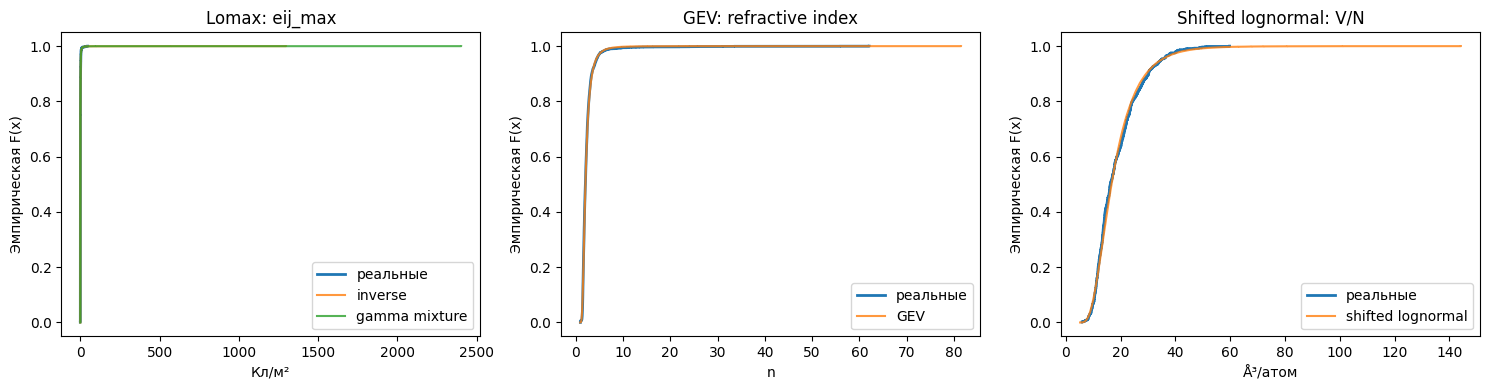

In [ ]:
def ecdf(a):
    s=np.sort(a); return s, np.arange(1,len(s)+1)/len(s)
fig, axes=plt.subplots(1,3,figsize=(15,4))
for ax, real, sims, title, xlabel in [
    (axes[0],x1,[(gen_lomax_inv,"inverse"),(gen_lomax_mix,"gamma mixture")],"Lomax: eij_max", "Кл/м²"),
    (axes[1],x2,[(gen_gev,"GEV")],"GEV: refractive index", "n"),
    (axes[2],x3,[(gen_lognorm,"shifted lognormal")],"Shifted lognormal: V/N", "Å³/атом")]:
    xx,yy=ecdf(real); ax.step(xx,yy,where="post",label="реальные",lw=2)
    for sim,name in sims:
        xx,yy=ecdf(sim); ax.step(xx,yy,where="post",label=name,alpha=.8)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Эмпирическая F(x)"); ax.legend()
plt.tight_layout(); plt.show()

### 5.1. Проверка адекватности модели на исходных данных

Проверка Колмогорова–Смирнова с параметрами, оценёнными на той же выборке, имеет некорректный стандартный нулевой закон. Поэтому используем параметрический bootstrap: генерируем выборки из fitted-модели, на каждой повторно оцениваем параметры и считаем KS-статистику. В SciPy это реализовано в `stats.goodness_of_fit`. Достаточно 199 повторов для учебной диагностики; для более точной оценки p-value число повторов следует увеличить (например, до 999 или 4999).

In [13]:
N_MC = 499

def gof_bootstrap(dist, data, known_params=None, statistic="ks", n_mc=N_MC, seed=SEED):
    known_params = {} if known_params is None else known_params
    return stats.goodness_of_fit(dist, np.asarray(data), known_params=known_params,
                                 statistic=statistic, n_mc_samples=n_mc,
                                 rng=np.random.default_rng(seed))

gof1 = gof_bootstrap(stats.lomax, x1, known_params={"loc":0.0}, seed=SEED)
gof2 = gof_bootstrap(stats.genextreme, x2, seed=SEED+1)
gof3 = gof_bootstrap(stats.lognorm, x3, seed=SEED+2)
gof_table = pd.DataFrame([
    {"RV":"X1 Lomax", "KS statistic":gof1.statistic, "bootstrap p":gof1.pvalue},
    {"RV":"X2 GEV", "KS statistic":gof2.statistic, "bootstrap p":gof2.pvalue},
    {"RV":"X3 shifted lognormal", "KS statistic":gof3.statistic, "bootstrap p":gof3.pvalue},
])
display(gof_table.round(5))
print("Правило при alpha=0.05: p<0.05 — отвергаем гипотезу о выбранном семействе; p>=0.05 — нет оснований отвергнуть.")

,RV,KS statistic,bootstrap p
0,X1 Lomax,0.02188,0.298
1,X2 GEV,0.03004,0.002
2,X3 shifted lognormal,0.04889,0.002


Правило при alpha=0.05: p<0.05 — отвергаем гипотезу о выбранном семействе; p>=0.05 — нет оснований отвергнуть.


<a id="consistency"></a>
## 6. Состоятельность оценок и эксперимент со сходимостью

Состоятельность — свойство последовательности оценок: при увеличении объёма выборки оценка сходится по вероятности к истинному параметру. Здесь генеральная совокупность в эксперименте — конечный эмпирический массив из 941 значения $X_1$. Для каждого $n$ много раз берём простую случайную выборку **без возвращения** и наблюдаем ошибку оценок относительно параметров, рассчитанных по всему массиву. Это демонстрация сходимости к характеристикам конечной эмпирической совокупности, а не строгое доказательство асимптотической состоятельности для неизвестной бесконечной популяции.

Дополнительно показываем параметр $\alpha$ fitted Lomax. При малых выборках MLE может быть неустойчивой или не иметь конечного максимума; неудачные подгонки отмечаем отдельно, а не маскируем произвольным отсечением. Дисперсию Lomax с $\alpha<2$ не используем как теоретическую цель, поскольку она бесконечна.

In [14]:
def consistency_experiment(data, sizes=(20,40,80,160,320,640,850), reps=250, seed=SEED):
    rng=np.random.default_rng(seed)
    pop_mean=float(np.mean(data)); pop_median=float(np.median(data))
    pop_q90=float(np.quantile(data,.90))
    rows=[]
    for n in sizes:
        vals={"mean":[],"median":[],"q90":[],"alpha_MLE":[]}
        alpha_fail=0
        for _ in range(reps):
            sample=rng.choice(data,size=n,replace=False)
            vals["mean"].append(np.mean(sample))
            vals["median"].append(np.median(sample))
            vals["q90"].append(np.quantile(sample,.90))
            try:
                aa=stats.lomax.fit(sample,floc=0)[0]
                if np.isfinite(aa) and aa < 1e6: vals["alpha_MLE"].append(aa)
                else: alpha_fail += 1
            except Exception:
                alpha_fail += 1
        truths={"mean":pop_mean,"median":pop_median,"q90":pop_q90,"alpha_MLE":alpha_hat}
        for key, estimates in vals.items():
            e=np.asarray(estimates)
            rows.append({"n":n,"оценка":key,"цель":truths[key],
                         "средняя оценка":np.mean(e) if len(e) else np.nan,
                         "bias":np.mean(e)-truths[key] if len(e) else np.nan,
                         "SD оценок":np.std(e,ddof=1) if len(e)>1 else np.nan,
                         "RMSE":np.sqrt(np.mean((e-truths[key])**2)) if len(e) else np.nan,
                         "доля неудачных alpha MLE":alpha_fail/reps if key=="alpha_MLE" else np.nan})
    return pd.DataFrame(rows)

consistency = consistency_experiment(x1)
display(consistency.round(5))

,n,оценка,цель,средняя оценка,bias,SD оценок,RMSE,доля неудачных alpha MLE
0,20,mean,0.76290,0.77524,0.01233,0.45775,0.45700,NaN
1,20,median,0.24772,0.27871,0.03098,0.11201,0.11600,NaN
2,20,q90,1.67810,1.62845,-0.04965,0.78989,0.78988,NaN
3,20,alpha_MLE,1.56797,3.26408,1.69611,11.56740,11.66629,0.076
4,40,mean,0.76290,0.77668,0.01377,0.39001,0.38948,NaN
5,40,median,0.24772,0.26755,0.01983,0.08091,0.08315,NaN
6,40,q90,1.67810,1.62319,-0.05491,0.64343,0.64449,NaN
7,40,alpha_MLE,1.56797,2.30364,0.73566,2.10638,2.22712,0.012
8,80,mean,0.76290,0.75157,-0.01133,0.25741,0.25714,NaN
9,80,median,0.24772,0.25317,0.00545,0.04961,0.04981,NaN


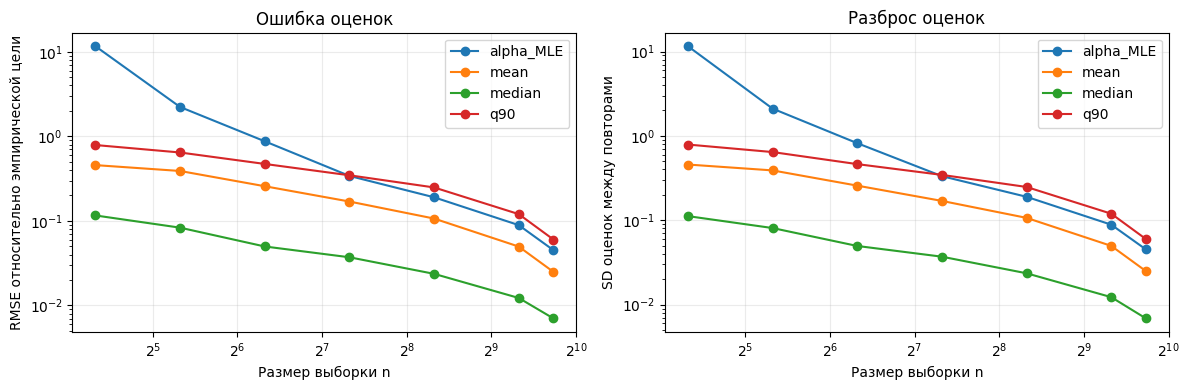

In [16]:
fig, axes=plt.subplots(1,2,figsize=(12,4))
for name, group in consistency.groupby("оценка"):
    axes[0].plot(group.n,group.RMSE,marker="o",label=name)
    axes[1].plot(group.n,group["SD оценок"],marker="o",label=name)
for ax in axes:
    ax.set_xscale("log",base=2); ax.set_yscale("log"); ax.set_xlabel("Размер выборки n"); ax.grid(alpha=.25); ax.legend()
axes[0].set_ylabel("RMSE относительно эмпирической цели"); axes[0].set_title("Ошибка оценок")
axes[1].set_ylabel("SD оценок между повторами"); axes[1].set_title("Разброс оценок")
plt.tight_layout(); plt.show()

<a id="benchmark"></a>
## 7. Сравнение вычислительных затрат

Сравним скорость двух генераторов Lomax. Время зависит от версии Python/NumPy, процессора и размера выборки; оно не является универсальной характеристикой метода. Для честного сравнения каждый метод получает собственный генератор с отдельным seed.

In [ ]:
def benchmark(fn, args, n=500_000, repeats=5):
    times=[]
    for i in range(repeats):
        rng=np.random.default_rng(SEED+i)
        t0=time.perf_counter(); values=fn(n,*args,rng=rng); times.append(time.perf_counter()-t0)
        assert len(values)==n
    return {"алгоритм":fn.__name__,"n":n,"повторов":repeats,
            "медианное время, с":np.median(times),"значений/с":n/np.median(times)}

bench = pd.DataFrame([
    benchmark(lomax_inverse,(alpha_hat,lambda_hat)),
    benchmark(lomax_gamma_mixture,(alpha_hat,lambda_hat))
])
display(bench.round(3))

,алгоритм,n,повторов,"медианное время, с",значений/с
0,lomax_inverse,500000,5,0.003,1.696396e+08
1,lomax_gamma_mixture,500000,5,0.022,2.281218e+07


<a id="resume"></a>
## 8. Итоговые выводы

### 8.1. Что установлено

- Для $e_{ij}^{\max}$ построены два независимых по конструкции генератора одного распределения: обратная функция и гамма-экспоненциальная смесь. Их теоретические распределения совпадают с Lomax.
- Для показателя преломления реализован GEV-генератор квантильным преобразованием.
- Для $V/N$ реализован генератор сдвинутого логнормального распределения: Box–Muller создаёт нормальную величину, далее применяются масштабирование, экспонента и сдвиг.
- Автотесты проверяют программный контракт и воспроизводимость. Статистические тесты дают вероятностные свидетельства, а не абсолютную гарантию качества.

### 8.2. Ограничения

- В Sprint 1 для GEV и сдвинутой логнормальной моделей бутстреп-проверки давали малые p-value. Поэтому генераторы корректно моделируют выбранные теоретические законы, но сами законы могут недостаточно хорошо описывать эмпирические данные.
- Сравнение двух конечных выборок зависит от размера выборки и случайной реализации. Большое N способно выявлять практически малые различия.
- Для Lomax при $\alpha<2$ дисперсия бесконечна; выборочная дисперсия конечной реализации не является оценкой конечного теоретического значения.
- Исходные данные получены вычислительными методами и отражают особенности отбора материалов, расчётных настроек и публикационной/базовой выборки.

### 8.3. Автоматический итог по goodness-of-fit

In [18]:
display(gof_table.assign(
    Решение=lambda d: np.where(d["bootstrap p"] < .05,
                               "H0 отвергается при 0.05", "H0 не отвергается при 0.05")
).round(5))

print("\nКраткий итог по параметрам:")
print(f"Lomax: alpha={alpha_hat:.4f}, lambda={lambda_hat:.4f}; E[X] существует={alpha_hat>1}; Var[X] конечна={alpha_hat>2}")
print(f"GEV: c={c_hat:.4f}, xi={xi_hat:.4f}, loc={mu_hat:.4f}, scale={sigma_hat:.4f}")
print(f"Shifted lognormal: shape={s_hat:.4f}, theta={theta_hat:.4f}, scale={scale_hat:.4f}")

,RV,KS statistic,bootstrap p,Решение
0,X1 Lomax,0.02188,0.298,H0 не отвергается при 0.05
1,X2 GEV,0.03004,0.002,H0 отвергается при 0.05
2,X3 shifted lognormal,0.04889,0.002,H0 отвергается при 0.05



Краткий итог по параметрам:
Lomax: alpha=1.5680, lambda=0.4734; E[X] существует=True; Var[X] конечна=False
GEV: c=-0.2807, xi=0.2807, loc=1.8716, scale=0.5126
Shifted lognormal: shape=0.5351, theta=3.9019, scale=12.8137


<a id="references"></a>
## 9. Литература

1. Lomax, K. S. (1954). Business failures: another example of the analysis of failure data. *Journal of the American Statistical Association*, 49, 847–852. Библиографическая запись: *JASA*, 49, 847–852 (1954); DOI следует сверить по каталогу издателя перед сдачей.
2. de Jong, M. et al. (2015). A database to enable discovery and design of piezoelectric materials. *Scientific Data*, 2, 150053. DOI: [10.1038/sdata.2015.53](https://doi.org/10.1038/sdata.2015.53).
3. Petousis, I. et al. (2017). High-throughput screening of inorganic compounds for the discovery of novel dielectric and optical materials. *Scientific Data*, 4, 160134. DOI: [10.1038/sdata.2016.134](https://doi.org/10.1038/sdata.2016.134).
4. Dunn, A. et al. (2020). Benchmarking materials property prediction methods: the Matbench test set and Automatminer reference algorithm. *npj Computational Materials*, 6, 138. DOI: [10.1038/s41524-020-00406-3](https://doi.org/10.1038/s41524-020-00406-3).